In [81]:
from pathlib import Path
import os
import pandas as pd
from dataclasses import dataclass
from datetime import datetime
import numpy as np
from pydantic import BaseModel
import sys
import scipy.signal as si
from librosa.feature import zero_crossing_rate
from copy import deepcopy
import json

sys.path.append("..")

In [96]:
path = Path(
    os.getenv("RAW_DATA_PATH", "data/raw")
)

In [97]:
folders = os.listdir(path)

# Base objects

In [4]:
from classes.sample.raw_data import INCFile, LMSFile

# Extract metadata

In [5]:
# records = []
# count = 0
# processed_docs = []
# for folder in folders:
#     if not folder.startswith("Teste"):
#         continue
#     files = os.listdir(path / folder)
#     prefixes = [f[:-8] for f in files if f.endswith(".txt")]
#     prefixes = np.unique(prefixes)
#     for prefix in prefixes:
#         if prefix in processed_docs:
#             continue
#         processed_docs.append(prefix)
#         lms_path = path / folder / f"{prefix}_LMS.txt"
#         inc_path = path / folder / f"{prefix}_INC.txt"
#         try:
#             inc_file = INCFile.from_txt(inc_path)
#             inc_meta = {
#                 "path": str(lms_path),
#                 "prefix": prefix,
#                 "temperature_inc": inc_file.temperature,
#                 "sampled_at": inc_file.sampled_at,
#                 "x1_avg": float(np.mean(inc_file.x1)),
#                 "x2_avg": float(np.mean(inc_file.x2)),
#                 "y1_avg": float(np.mean(inc_file.y1)),
#                 "y2_avg": float(np.mean(inc_file.y2)),
#             }
#         except:
#             inc_meta = {
#                 "path": str(lms_path),
#                 "prefix": prefix,
#                 "temperature_inc": None,
#                 "sampled_at": None,
#                 "x1_avg": None,
#                 "x2_avg": None,
#                 "y1_avg": None,
#                 "y2_avg": None,
#             }
#         try:
#             lms_file = LMSFile.from_txt(lms_path)
#             lms_meta = {
#                 "s1_avg": float(np.mean(lms_file.s1)),
#                 "s2_avg": float(np.mean(lms_file.s2)),
#                 "s3_avg": float(np.mean(lms_file.s3)),
#                 "s4_avg": float(np.mean(lms_file.s4)),
#                 "dt": lms_file.dt,
#                 "temperature_lms": lms_file.temperature,
#             }
#         except:
#             lms_meta = {
#                 "s1_avg": None,
#                 "s2_avg": None,
#                 "s3_avg": None,
#                 "s4_avg": None,
#                 "dt": None,
#                 "temperature_lms": None,
#             }

#         record = {}
#         record.update(inc_meta)
#         record.update(lms_meta)
#         records.append(record)
#         count += 1

In [6]:
# records_df = pd.DataFrame(records)
# output_path = Path("../data/metadata")
# records_df.to_csv(output_path / "meta_3.csv")

# Extract features

In [91]:
class Record(BaseModel):
    sampled_at: datetime
    band_id: str
    cable: str
    axis: str
    tension: float
    rms: float
    median_zero_crossing_freq: float
    median_zero_crossing_freq_demod: float
    rms_demod: float
    

def get_zc_freq(signal: pd.Series) -> float:
    dt = signal.index[1] - signal.index[0]
    data = signal.to_numpy()
    zc = zero_crossing_rate(data).reshape(-1)
    zcm = np.median(zc)
    return zcm / 2  / dt

In [92]:
def bandpass(x: pd.DataFrame, f1: float, f2: float):
    dt = x.index[1] - x.index[0]
    h = si.firwin(127, [f1, f2], fs=1/dt, pass_zero="bandpass")
    return x.apply(lambda xx: si.lfilter(h, 1, xx))

def demod(x: pd.DataFrame):
    return x.apply(lambda xx: np.abs(si.hilbert(xx)))

In [93]:
def get_band_features_from_lms(lms: LMSFile, bandwidth: float) -> list[Record]:
    sampled_at = lms.sampled_at
    dt = lms.dt
    fs = 1 / dt
    num_samples = len(lms.c2_y)
    t = np.linspace(0, num_samples * dt, num_samples)
    f_max = fs / 2

    # -- getting signal dataframe --
    records = []
    for cable in ["c1", "c2", "c3", "c4"]:
        tension = np.mean(getattr(lms, f"s{cable[-1]}"))
        for ax in ["x", "y", "z"]:
            signal = pd.DataFrame({"x": getattr(lms, f"{cable}_{ax}")})
            signal.index = t

            # -- extract features per band --
            band_features = {}
            for f_start in np.arange(0.1, f_max, bandwidth):
                if f_start > f_max:
                    break
                f_end = min(f_start + bandwidth, f_max-0.1)
                band_id = str(round(f_start, 1)) + "_" + str(round(f_end, 1))
                signal_filt = bandpass(deepcopy(signal), f1=f_start, f2=f_end)
                signal_demod = demod(signal_filt)
                signal_demod_filt = bandpass(signal_demod - signal_demod.mean(), f1=0.1, f2=10)
                median_zero_crossing_freq = get_zc_freq(signal_filt["x"])
                median_zero_crossing_freq_demod = get_zc_freq(signal_demod_filt["x"])
                record = Record(
                    sampled_at=sampled_at,
                    median_zero_crossing_freq=median_zero_crossing_freq,
                    cable=cable,
                    axis=ax,
                    tension=tension,
                    band_id=band_id,
                    rms=np.sqrt(np.mean(np.square(signal_filt))),
                    rms_demod=np.sqrt(np.mean(np.square(signal_demod_filt))),
                    median_zero_crossing_freq_demod=median_zero_crossing_freq_demod
                )
                records.append(record.dict())
    return records

In [98]:
records = []
count = 0
processed_docs = []
for folder in folders:
    if not folder.startswith("Teste"):
        continue
    files = os.listdir(path / folder)
    prefixes = [f[:-8] for f in files if f.endswith(".txt")]
    prefixes = np.unique(prefixes)
    for prefix in prefixes:
        if prefix in processed_docs:
            continue
        processed_docs.append(prefix)
        lms_path = path / folder / f"{prefix}_LMS.txt"
        try:
            lms_file = LMSFile.from_txt(lms_path)
        except:
            continue
        rec = get_band_features_from_lms(lms_file, bandwidth=10)
        records += rec
        count += 1

In [99]:
records_df = pd.DataFrame(records)
output_path = Path("../data/features")
records_df.to_csv(output_path / "features_1.csv")

# tests

In [100]:
records_df = records_df.sort_values("sampled_at")

In [101]:
meta = pd.read_csv("../data/metadata/meta_1.csv")
meta = meta.sort_values("sampled_at")

In [102]:
px.line(meta, x="sampled_at", y="s1_avg")

In [103]:
import plotly.express as px

In [112]:
px.line(
    records_df.loc[(records_df.axis == "y") & (records_df.sampled_at > datetime(2023,1,10))],
    x="sampled_at",
    y="median_zero_crossing_freq_demod",
    color="band_id",
    facet_col="cable",
)

In [105]:
px.line(
    records_df.loc[(records_df.axis == "y") & (records_df.sampled_at > datetime(2023,1,10))],
    x="tension",
    y="median_zero_crossing_freq",
    color="band_id",
    facet_col="cable",
)

In [106]:
px.line(
    records_df.loc[(records_df.axis == "y") & (records_df.sampled_at > datetime(2023,1,10))],
    x="tension",
    y="median_zero_crossing_freq",
    color="band_id",
    facet_col="cable",
)

In [107]:
px.scatter(
    records_df.loc[(records_df.axis == "y") & (records_df.sampled_at > datetime(2023,1,10))].sort_values("band_id"),
    color="rms",
    y="tension",
    x="band_id",
    facet_col="cable",
)

In [108]:
import matplotlib.pyplot as plt

In [109]:
temp = records_df.loc[(records_df.cable=="c1") & (records_df.axis == "z") & (records_df.sampled_at > datetime(2023,1,10))].sort_values("band_id")
temp = temp.pivot(index="sampled_at", columns="band_id", values="rms")

In [110]:
tempgb = temp.groupby(pd.Grouper(freq='4D')).mean()
xx = tempgb.to_numpy()
tens = tempgb.index.to_numpy()
bands = np.sort([float(col.split("_")[0]) for col in tempgb.columns])

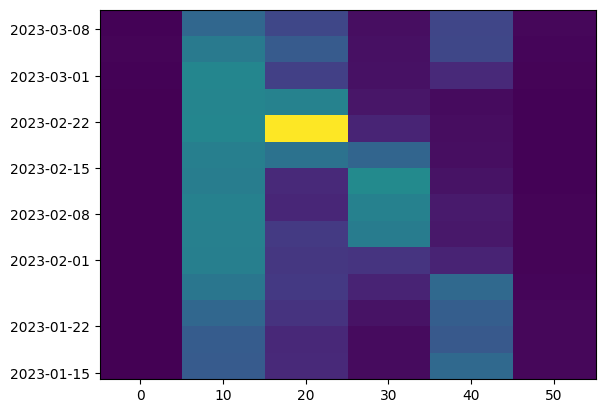

In [111]:
ind = bands < 60
plt.pcolormesh(bands[ind], tens, xx[:,ind])